# Stage 4: Exploratory Data Analysis (EDA)
EDA helps us understand the target distribution and relationships between phone specifications and used price.

In [1]:
from pathlib import Path
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "data"
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = DATA_DIR / "used_phones_cleaned.csv"
df = pd.read_csv(DATA_PATH)
TARGET = "normalized_used_price"  # Confirm target name.
sns.set_theme(style="whitegrid")
df.head()

,device_brand,os,screen_size,4g,5g,rear_camera_mp,front_camera_mp,internal_memory,ram,battery,weight,release_year,days_used,normalized_used_price,normalized_new_price
0,Honor,Android,14.50,yes,no,13.0,5.0,64.0,3.0,3020.0,146.0,2020,127,4.307572,4.715100
1,Honor,Android,17.30,yes,yes,13.0,16.0,128.0,8.0,4300.0,213.0,2020,325,5.162097,5.519018
2,Honor,Android,16.69,yes,yes,13.0,8.0,128.0,8.0,4200.0,213.0,2020,162,5.111084,5.884631
3,Honor,Android,25.50,yes,yes,13.0,8.0,64.0,6.0,7250.0,480.0,2020,345,5.135387,5.630961
4,Honor,Android,15.32,yes,no,13.0,8.0,64.0,3.0,5000.0,185.0,2020,293,4.389995,4.947837


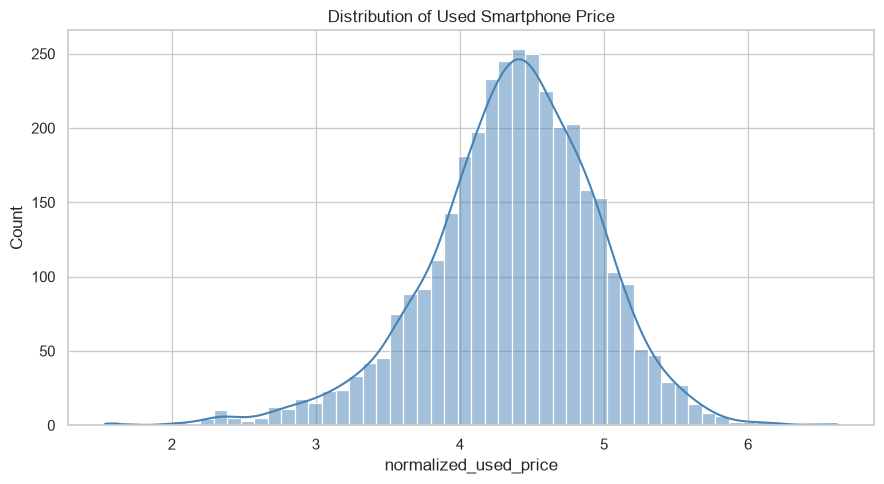

In [2]:
plt.figure(figsize=(9,5))
sns.histplot(df[TARGET], kde=True, color="steelblue")
plt.title("Distribution of Used Smartphone Price")
plt.xlabel(TARGET)
plt.tight_layout()
plt.show()

In [3]:
brand_col = next((c for c in df.columns if c.lower() in {"brand_name","brand","manufacturer"}), None)
if brand_col:
    top_brands = df[brand_col].value_counts().head(15).index
    plt.figure(figsize=(10,6))
    sns.countplot(data=df[df[brand_col].isin(top_brands)], y=brand_col,
                  order=df[brand_col].value_counts().head(15).index, color="steelblue")
    plt.title("Most Frequent Smartphone Brands")
    plt.tight_layout()
    plt.show()
else:
    print("No recognizable brand column found.")

No recognizable brand column found.


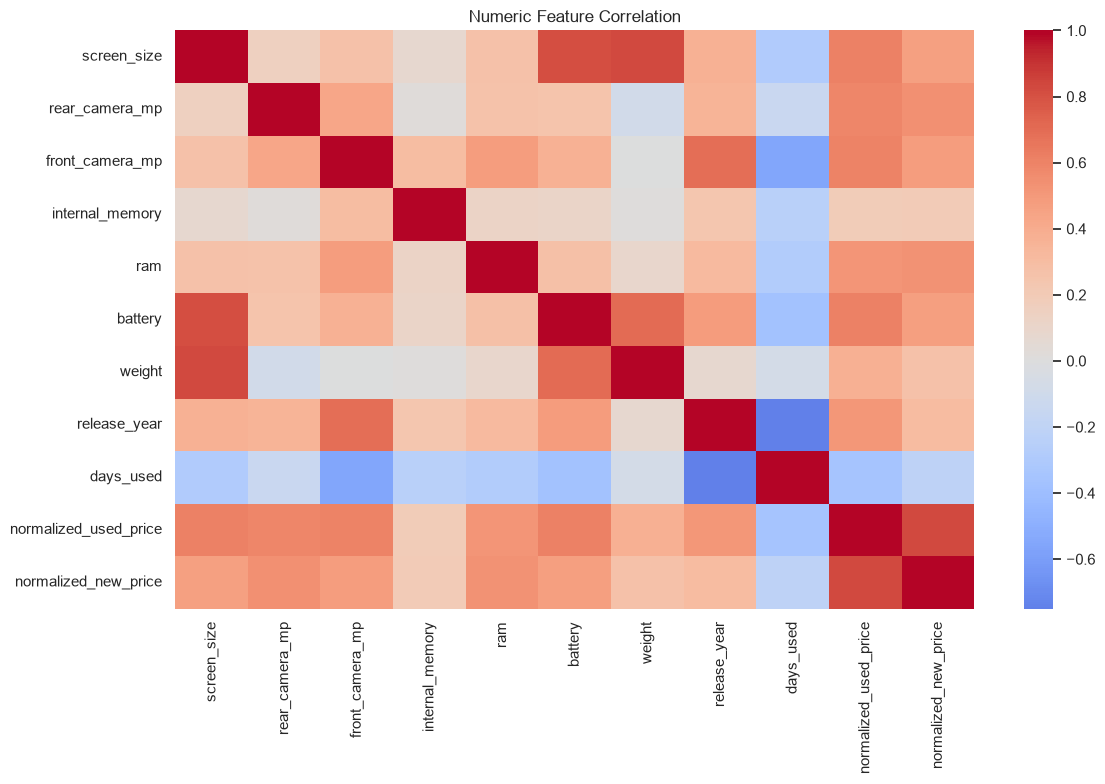

In [4]:
numeric = df.select_dtypes(include="number")
plt.figure(figsize=(12,8))
sns.heatmap(numeric.corr(), cmap="coolwarm", center=0)
plt.title("Numeric Feature Correlation")
plt.tight_layout()
plt.show()

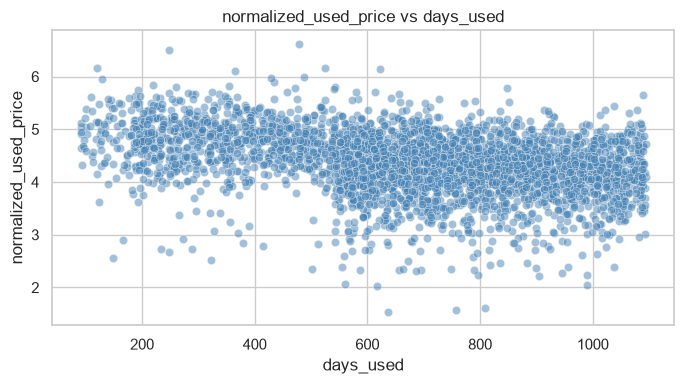

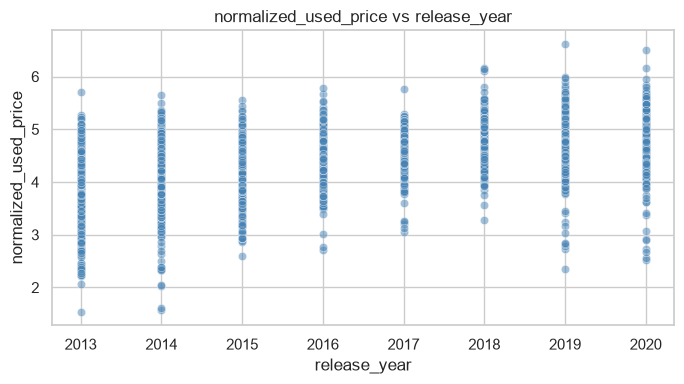

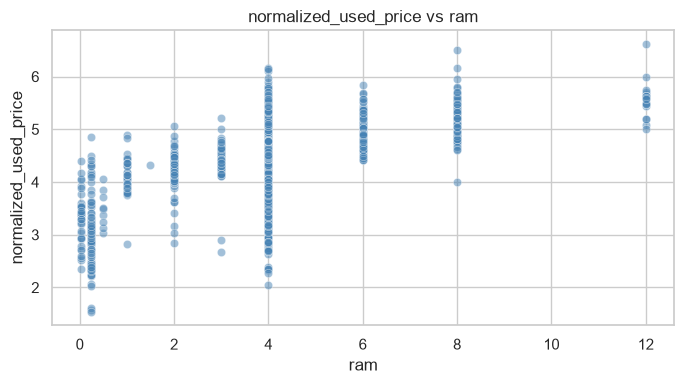

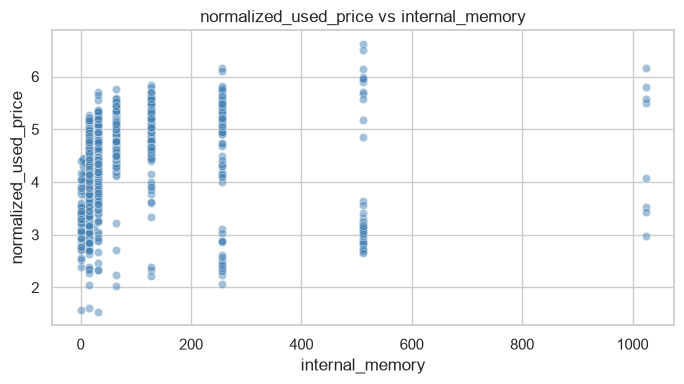

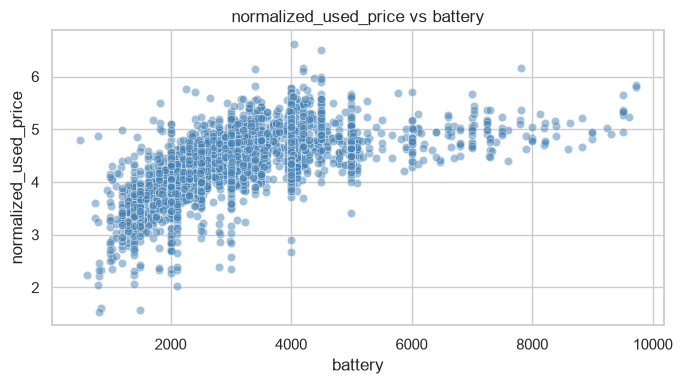

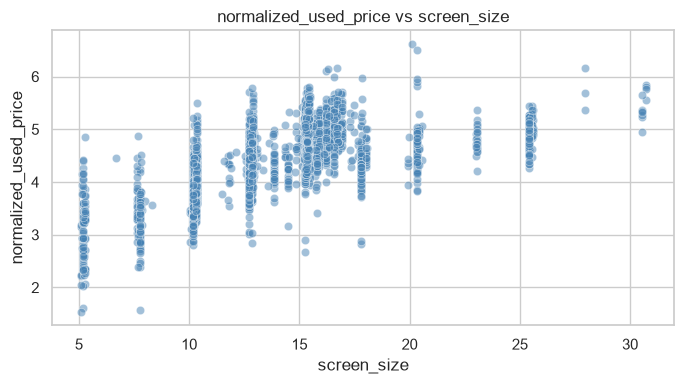

In [5]:
for feature in ["days_used","release_year","ram","internal_memory","battery","screen_size"]:
    if feature in df.columns:
        plt.figure(figsize=(7,4))
        sns.scatterplot(data=df, x=feature, y=TARGET, alpha=.5, color="steelblue")
        plt.title(f"{TARGET} vs {feature}")
        plt.tight_layout()
        plt.show()

## EDA questions to answer
1. Which brands are most represented?
2. How is the target price distributed?
3. Does longer usage appear associated with a lower used price?
4. Which hardware features appear associated with price?
5. Are there outliers or imbalanced brand categories?

Write observations based on your actual charts; do not invent findings.